In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from ic.config import Cifar10Config, PathsConfig
from ic.datasets.cifar10 import get_class_names, load_cifar10
from ic.modeling.cnn import build_cifar10_cnn
from ic.modeling.evaluate import evaluate_classifier
from ic.modeling.predict import predict_images
from ic.modeling.train import train_image_classifier
from ic.plots import plot_confusion_matrix, plot_training_history

config = Cifar10Config()
paths = PathsConfig()
class_names = get_class_names()

# Carregar a base de Dados CIFAR-10

In [ ]:
data = load_cifar10()
X_train, y_train = data.x_train, data.y_train
X_test, y_test = data.x_test, data.y_test

print(f"Formato de X_train: {X_train.shape}")
print(f"Formato de y_train: {y_train.shape}")
print(f"Formato de X_test: {X_test.shape}")
print(f"Formato de y_test: {y_test.shape}")

Formato de X_train:  (50000, 32, 32, 3)
Formato de y_train:  (50000,)
Formato de X_test:  (10000, 32, 32, 3)
Formato de y_test:  (10000,)


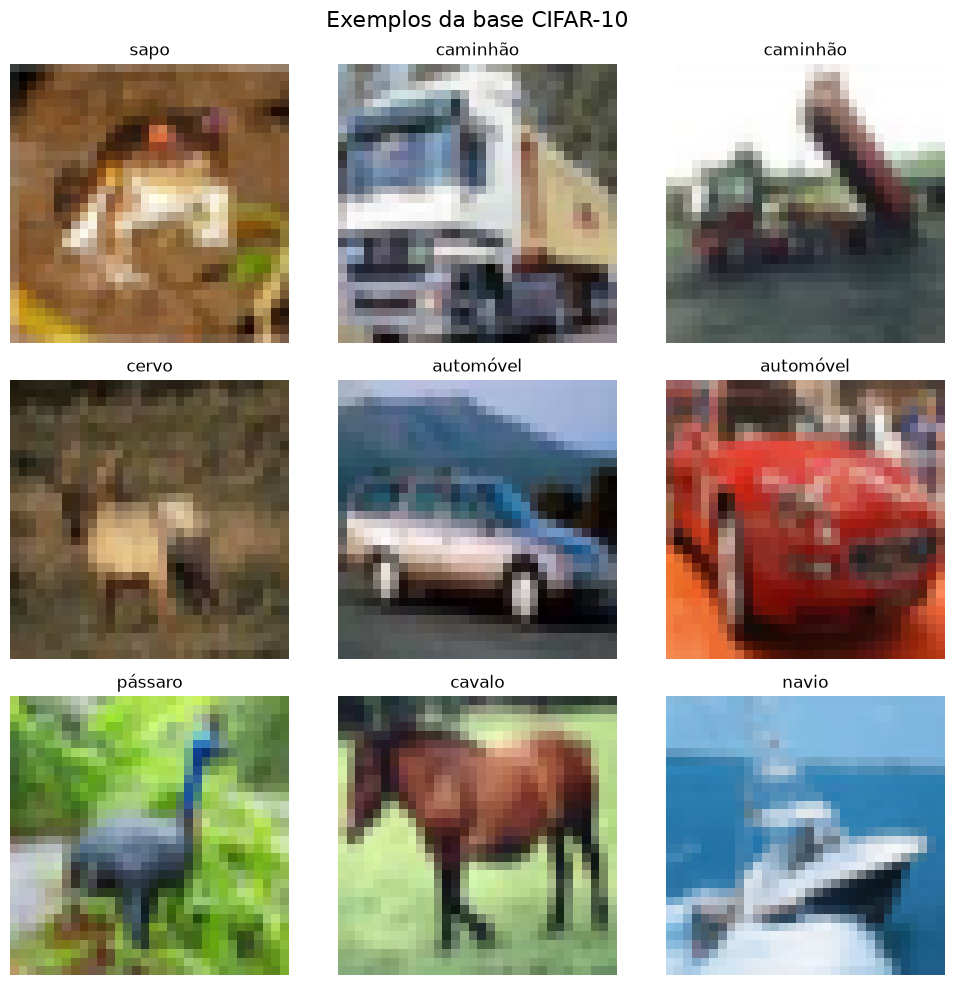

In [14]:
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3,i+1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")
plt.suptitle("Exemplos da base CIFAR-10", fontsize=16)
plt.tight_layout()
plt.show()

Criação do modelo CNN

In [ ]:
model = build_cifar10_cnn(config)
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 282,250 (1.08 MB)

 Trainable params: 282,250 (1.08 MB)

 Non-trainable params: 0 (0.00 B)

Treinar Rede


In [ ]:
checkpoint_path = paths.checkpoints_dir / config.model_name
history = train_image_classifier(model, data, config, checkpoint_path)

Epoch 1/20


W0000 00:00:1790979777.002126    5290 cpu_allocator_impl.cc:174] Allocation of 491520000 exceeds 10% of free system memory.


625/625 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.4446 - loss: 1.5481

W0000 00:00:1790979814.609618    5290 cpu_allocator_impl.cc:174] Allocation of 122880000 exceeds 10% of free system memory.


625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 64ms/step - accuracy: 0.4446 - loss: 1.5481 - val_accuracy: 0.5412 - val_loss: 1.3027
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 39s 62ms/step - accuracy: 0.5839 - loss: 1.1710 - val_accuracy: 0.6080 - val_loss: 1.1254
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 61ms/step - accuracy: 0.6389 - loss: 1.0247 - val_accuracy: 0.6399 - val_loss: 1.0276
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.6777 - loss: 0.9309 - val_accuracy: 0.6687 - val_loss: 0.9562
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 41s 65ms/step - accuracy: 0.7010 - loss: 0.8618 - val_accuracy: 0.6824 - val_loss: 0.9193
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 60ms/step - accuracy: 0.7204 - loss: 0.8038 - val_accuracy: 0.6903 - val_loss: 0.9022
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 38s 61ms/step - accuracy: 0.7397 - loss: 0.7533 - val_accuracy: 0.6943 - val_loss: 0.8991
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 40s 60ms/step - accuracy: 0.7559 - loss: 0.7035 - val_accurac

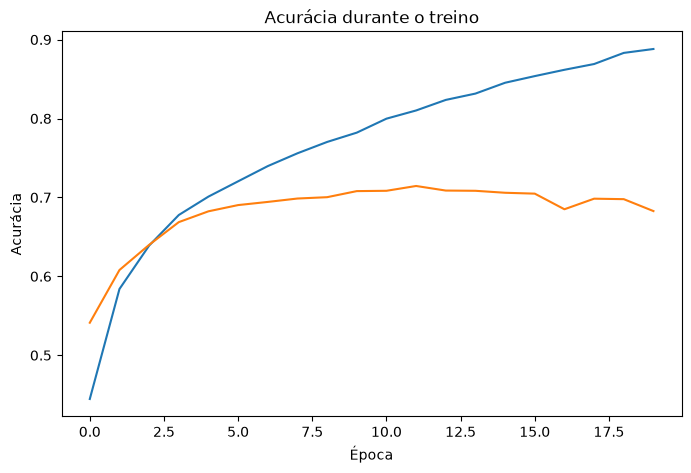

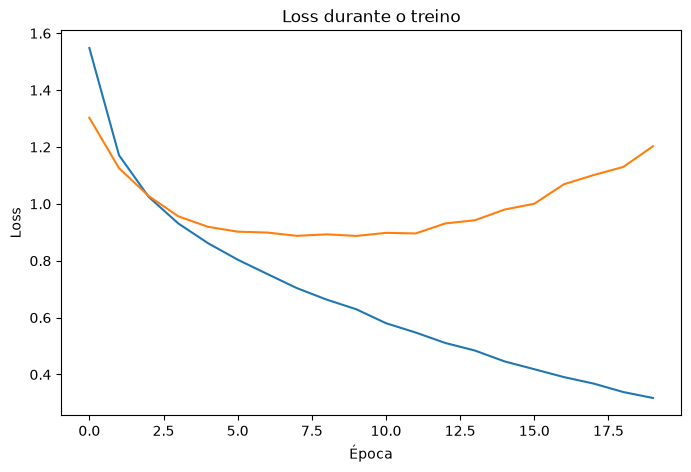

In [ ]:
plot_training_history(history, paths.reports_dir / "figures" / "cifar10_training.png")

In [ ]:
results = evaluate_classifier(model, X_test, y_test)
print({name: round(value, 4) for name, value in results.items()})

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6818 - loss: 1.2454
Acurácia no teste: 68.18%
Perda no teste: 1.25


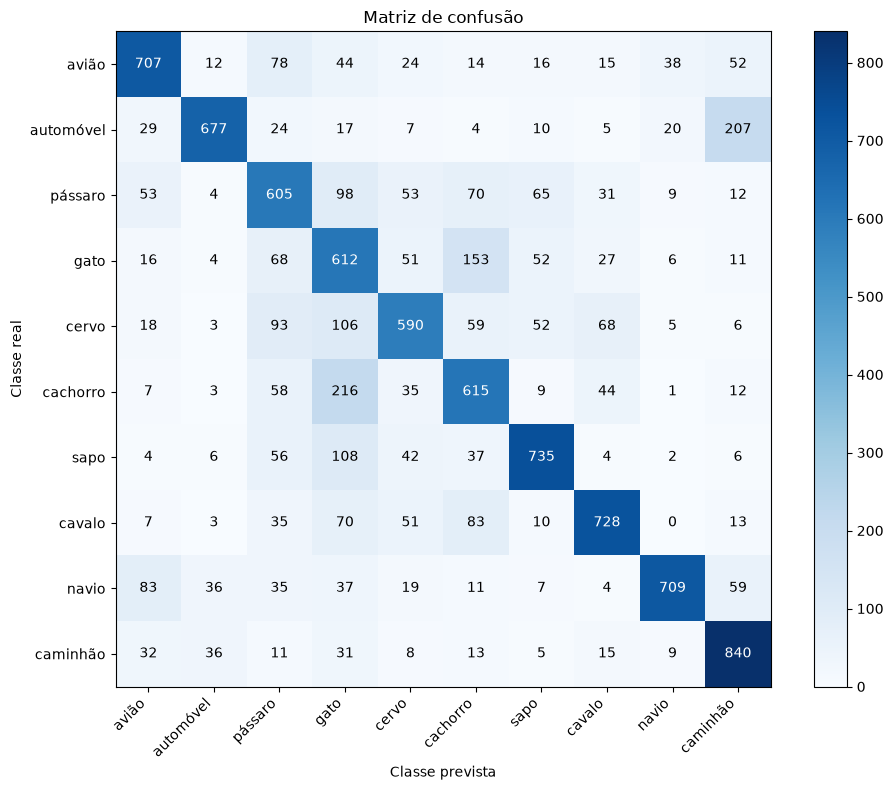

In [ ]:
pred_probs_test = predict_images(model, X_test)
y_pred = np.argmax(pred_probs_test, axis=1)
confusion_matrix = tf.math.confusion_matrix(
    y_test,
    y_pred,
    num_classes=len(class_names),
).numpy()
plot_confusion_matrix(
    confusion_matrix,
    class_names,
    paths.reports_dir / "figures" / "cifar10_confusion_matrix.png",
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step


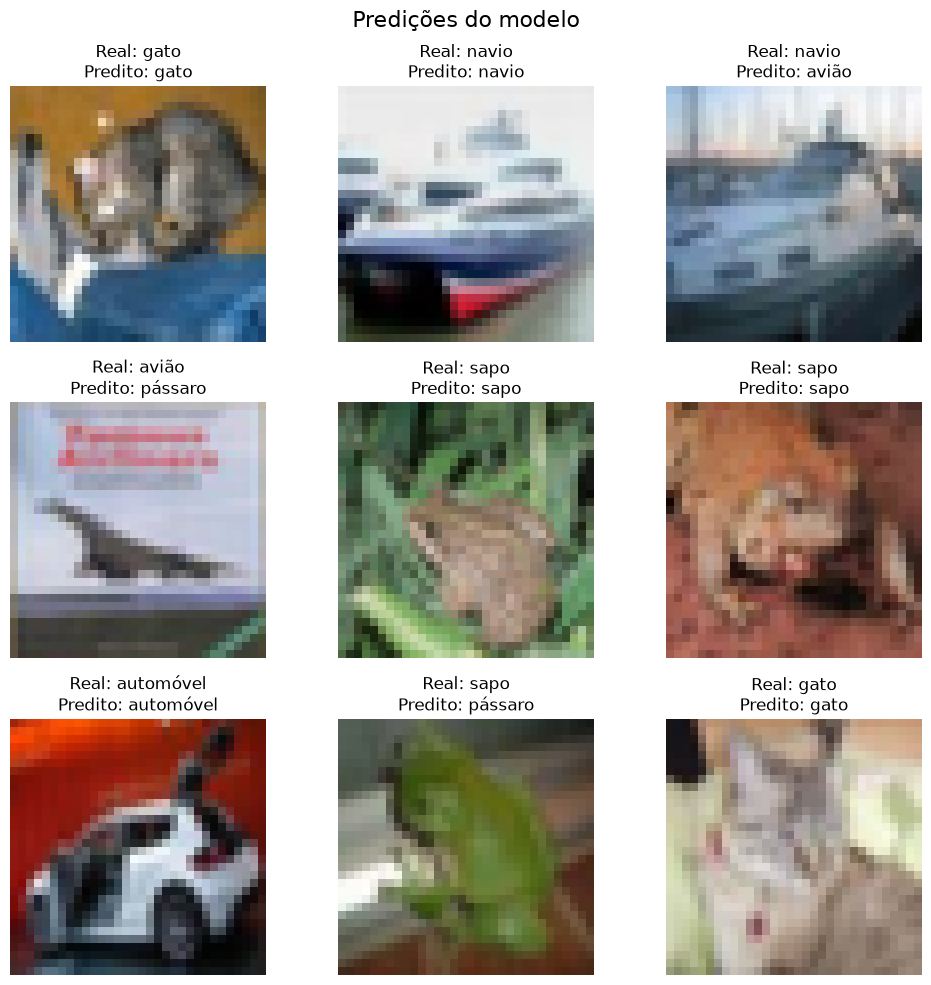

In [ ]:
pred_probs = predict_images(model, X_test[0:9])
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_test[i])
    real_label = class_names[y_test[i]]
    pred_label = class_names[np.argmax(pred_probs[i])]
    plt.title(f"Real: {real_label}\nPredito: {pred_label}")
    plt.axis("off")
plt.suptitle("Predições do modelo", fontsize=16)
plt.tight_layout()
plt.show()